In [ ]:
import pandas as pd
from sklearn.impute import KNNImputer
import matplotlib.pyplot as plt

In [211]:
def clean_dataset(df: pd.DataFrame):
    imputer = KNNImputer()
    df["CryoSleep"] = df["CryoSleep"].astype("bool")
    df["VIP"] = df["VIP"].astype("bool")   
    for col in df.columns:
        most_occuring_value = max(df[col].value_counts().values)
        if most_occuring_value < 5:
            df = df.drop(columns=[col])
    numerical_cols = df.select_dtypes(include=["int", "float"]).columns
    text_cols = df.select_dtypes(include=["str", "object"]).columns
    df[numerical_cols] = imputer.fit_transform(df[numerical_cols])
    df[text_cols] = df[text_cols].fillna("Unknown")
    return df

In [212]:
df_train = clean_dataset(pd.read_csv("./Data/train.csv"))
df_test = clean_dataset(pd.read_csv("./Data/test.csv"))

In [213]:
df_train.head()

,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported
0,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,False
1,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,True
2,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,False
3,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,False
4,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,True


In [214]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   HomePlanet    8693 non-null   str    
 1   CryoSleep     8693 non-null   bool   
 2   Cabin         8693 non-null   str    
 3   Destination   8693 non-null   str    
 4   Age           8693 non-null   float64
 5   VIP           8693 non-null   bool   
 6   RoomService   8693 non-null   float64
 7   FoodCourt     8693 non-null   float64
 8   ShoppingMall  8693 non-null   float64
 9   Spa           8693 non-null   float64
 10  VRDeck        8693 non-null   float64
 11  Transported   8693 non-null   bool   
dtypes: bool(3), float64(6), str(3)
memory usage: 636.8 KB


In [215]:
df_train.isna().sum()

HomePlanet      0
CryoSleep       0
Cabin           0
Destination     0
Age             0
VIP             0
RoomService     0
FoodCourt       0
ShoppingMall    0
Spa             0
VRDeck          0
Transported     0
dtype: int64

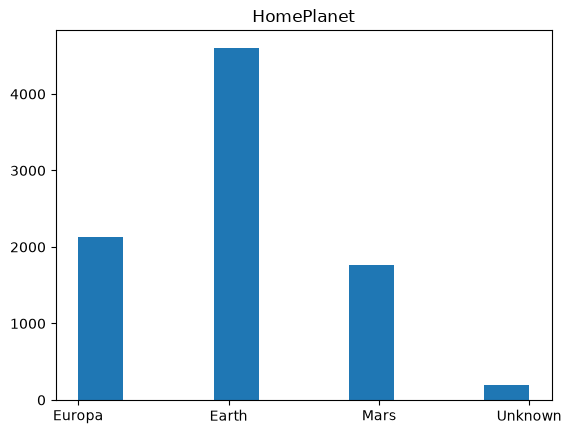

c:\Users\Willi\.virtualenvs\Space-titanic-BpK7nQOU\Lib\site-packages\matplotlib\axes\_axes.py:7515: RuntimeWarning: Converting input from bool to <class 'numpy.uint8'> for compatibility.
  m, bins = np.histogram(x[i], bins, weights=w[i], **hist_kwargs)


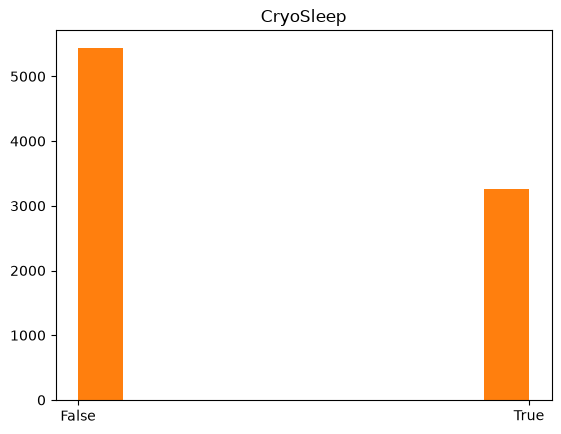

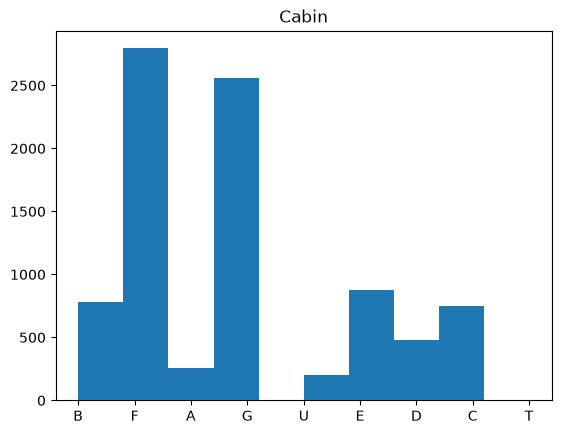

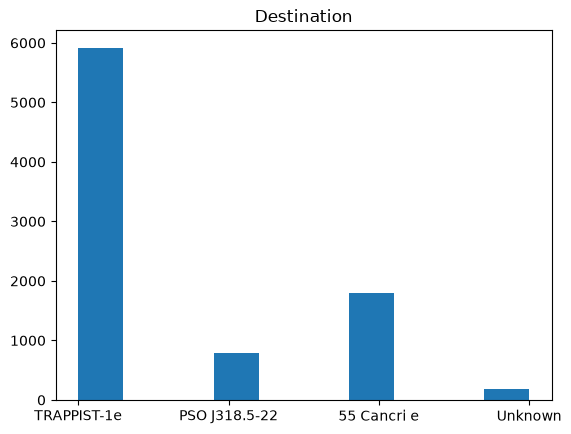

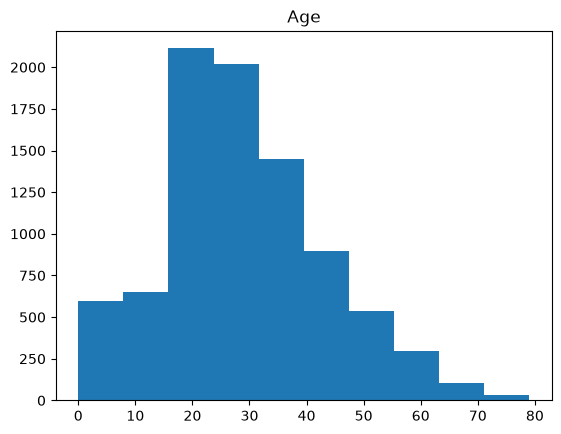

c:\Users\Willi\.virtualenvs\Space-titanic-BpK7nQOU\Lib\site-packages\matplotlib\axes\_axes.py:7515: RuntimeWarning: Converting input from bool to <class 'numpy.uint8'> for compatibility.
  m, bins = np.histogram(x[i], bins, weights=w[i], **hist_kwargs)


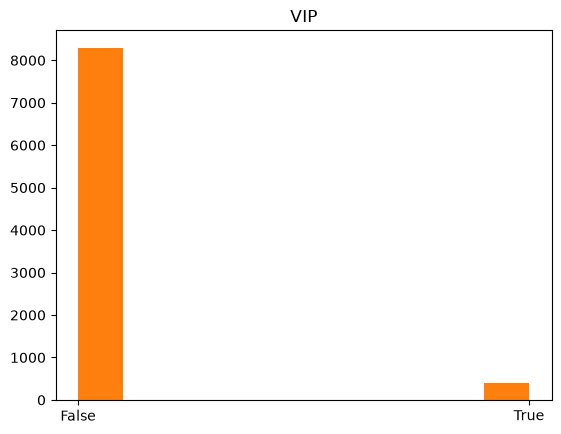

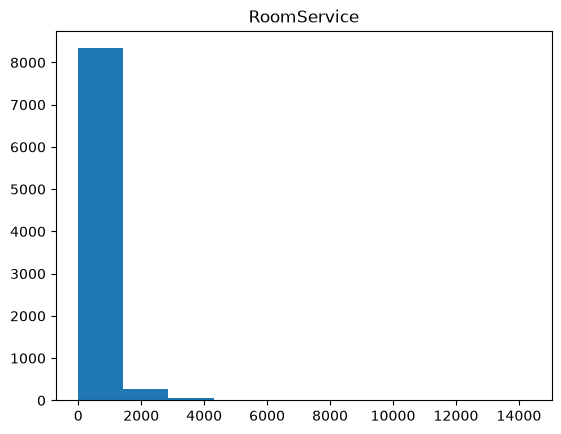

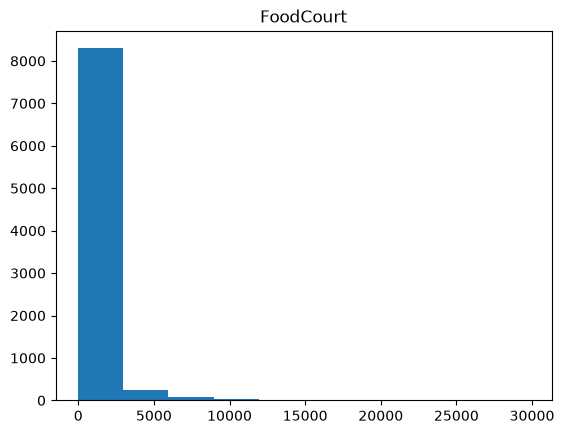

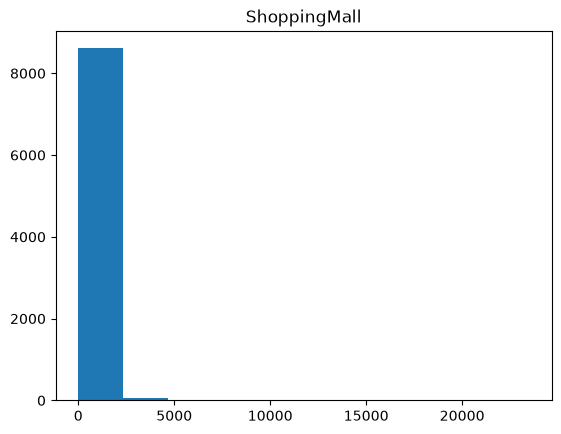

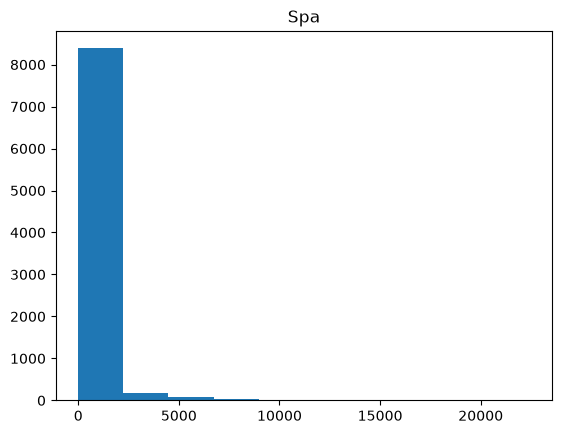

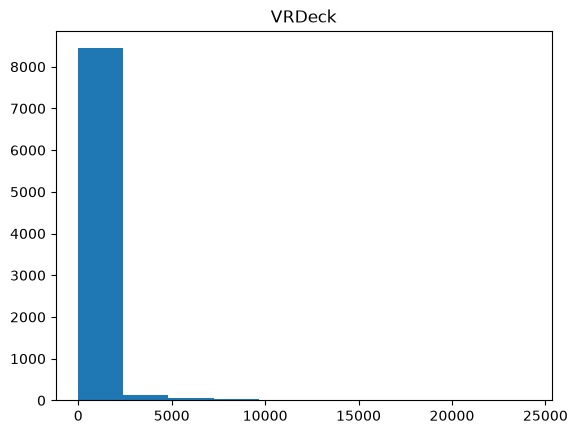

c:\Users\Willi\.virtualenvs\Space-titanic-BpK7nQOU\Lib\site-packages\matplotlib\axes\_axes.py:7515: RuntimeWarning: Converting input from bool to <class 'numpy.uint8'> for compatibility.
  m, bins = np.histogram(x[i], bins, weights=w[i], **hist_kwargs)


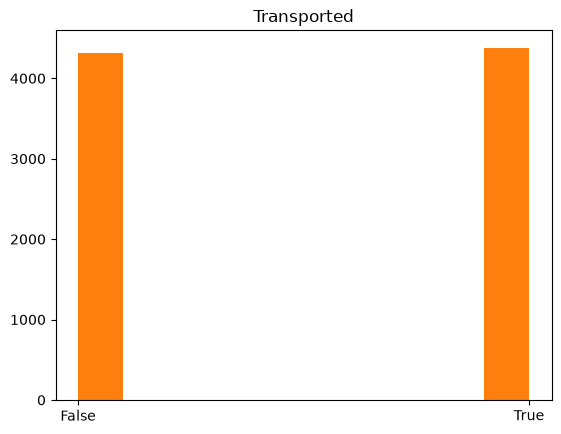

In [216]:
for col in df_train.columns:
    plt.title(col)
    if col == "Cabin":
        plt.hist(df_train[col].str[0:1].str.strip())
    else:
        try:
            plt.hist(df_train[col])
        except:
            plt.hist(df_train[col].astype("str"))
    plt.show()

In [217]:
df_train.to_csv("./Data/train_cleaned.csv", index=False)
df_test.to_csv("./Data/test_cleaned.csv", index=False)